# Direct vs structural points predictor, 2023-24 and 2024-25

Both predictors give every player with a fixture a predicted score for the next gameweek, walk-forward (a gameweek is
predicted only from earlier gameweeks).

| | Direct predictor | Structural predictor |
|---|---|---|
| Code (all under `playground/predictors/`) | `23-24/src`, `24-25/predictor/src` | `structural/src` |
| Predictions | `models/predictions.csv` | `outputs/{season}/structural_predictions_history_{prev}.csv` |
| What it fits | the player's FPL points for the gameweek (`config.TARGET = "total_points"`, summed over both fixtures in a double gameweek), one regression per position; the model is re-chosen from 9 base models + 2 ensembles at each selection point by validation MAE | each scoring component (minutes, goals conceded, goals, assists, bonus, saves, cards), combined with the FPL scoring rules |
| Training data | the current season only: every player with a fixture who had minutes in the previous 3 gameweeks (`data.training_rows`); `n_fixtures` is an input | the current season plus the previous one (the deployed setting); the season-only run is also shown |
| Rows | one per player and gameweek (features of the first fixture in a double gameweek) | one per player and fixture (summed to the gameweek here) |

Both predict the same thing (points) for the same players, so the comparison is between the two ways of modelling it.

**How they are compared**

* **Actual score:** each player's realised FPL `total_points` for the gameweek, summed over both fixtures in a double
  gameweek. Both files carry it; the loader checks that they agree.
* **Gameweeks 6-38.** The direct model's GW5 predictions were used to select that model (`in_selection`), so GW5 is left out
  for both.
* **Same rows.** Both files cover exactly the same player-gameweeks (checked below), so every score is paired.
* **Two populations:** every player with a fixture (what the optimiser chooses from) and players who played (minutes > 0).
* **Metrics:** RMSE (the optimiser needs the mean, which squared error targets), MAE, R², bias (predicted − actual), and
  Spearman rank correlation, pooled and averaged within each gameweek (picking a team is a ranking within a gameweek).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr, t as t_dist, wilcoxon

ROOT = Path("..").resolve()  # run from working/
STRUCT = ROOT / "structural/outputs"
SEASONS = {
    "23-24": {
        "direct": ROOT / "direct_predictor/23-24/predictions.csv",
        "history": "22-23",
    },
    "24-25": {
        "direct": ROOT / "direct_predictor/24-25/predictions.csv",
        "history": "23-24",
    },
}
FIRST_GW = 6
POS = ["GK", "DEF", "MID", "FWD"]
SQUAD = {
    "GK": 2,
    "DEF": 5,
    "MID": 5,
    "FWD": 3,
}  # top-k per position for the decision check

LABEL = {
    "direct": "Direct",
    "struct": "Structural",
    "struct_season": "Structural, season only",
    "struct_if_plays": "Structural, if plays",
}
COLOR = {"direct": "#eb6834", "struct": "#2a78d6", "struct_season": "#8a8f98"}
STYLE = {
    "direct": {"ls": "--", "marker": "s"},
    "struct": {"ls": "-", "marker": "o"},
    "struct_season": {"ls": ":", "marker": "^"},
}
INK, GREY = "#22252b", "#8a8f98"

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 9,
        "axes.titlesize": 9,
        "axes.labelsize": 9,
        "legend.fontsize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#5b6068",
        "axes.grid": True,
        "grid.color": "#e3e5e8",
        "grid.linewidth": 0.6,
        "lines.linewidth": 1.6,
        "lines.markersize": 3,
        "figure.dpi": 120,
        "legend.frameon": False,
    }
)
pd.set_option("display.precision", 3)

FIG = Path("figures")  # thesis figures (PDF)


def save(fig, name):
    FIG.mkdir(exist_ok=True)
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")


## 1. Load and align the predictions

In [2]:
def per_gameweek(path):
    # structural rows are per fixture: sum predictions and points to the gameweek
    s = pd.read_csv(path)
    return (
        s.groupby(["round", "fpl_id"])
        .agg(
            pos=("pos", "first"),
            name=("name", "first"),
            team=("team", "first"),
            n_fixtures=("n_fixtures", "first"),
            total_points=("total_points", "sum"),
            minutes=("minutes", "sum"),
            played=("played", "max"),
            struct=("pred", "sum"),
            struct_if_plays=("pred_if_plays", "sum"),
        )
        .reset_index()
    )


def load(season):
    cfg = SEASONS[season]
    d = pd.read_csv(
        cfg["direct"],
        usecols=[
            "pos",
            "round",
            "fpl_id",
            "model",
            "pred",
            "xP",
            "in_selection",
            "total_points",
        ],
    )
    d = d.rename(columns={"total_points": "points_direct"})
    s = per_gameweek(
        STRUCT / season / f"structural_predictions_history_{cfg['history']}.csv"
    )
    s1 = per_gameweek(STRUCT / season / "structural_predictions.csv")[
        ["round", "fpl_id", "struct"]
    ]
    m = s.merge(
        d.rename(columns={"pred": "direct", "pos": "pos_direct"}),
        on=["round", "fpl_id"],
        how="inner",
        validate="1:1",
    ).merge(
        s1.rename(columns={"struct": "struct_season"}),
        on=["round", "fpl_id"],
        how="left",
        validate="1:1",
    )
    # the structural history run also has GW1-4; every direct row must find its structural row
    assert len(m) == len(d), (
        f"{season}: {len(d) - len(m)} direct rows have no structural row"
    )
    assert len(s[s["round"] >= d["round"].min()]) == len(d), (
        f"{season}: structural has rows the direct file lacks"
    )
    assert (m["pos"] == m["pos_direct"]).all()
    assert m["struct_season"].notna().all()
    agree = (m["points_direct"] == m["total_points"]).mean()
    assert agree > 0.999, f"{season}: actual points agree on only {agree:.2%} of rows"
    m = m[(m["round"] >= FIRST_GW) & ~m["in_selection"]].drop(
        columns=["pos_direct", "in_selection", "points_direct"]
    )
    m.insert(0, "season", season)
    return m.reset_index(drop=True)


data = {s: load(s) for s in SEASONS}
pd.DataFrame(
    {
        s: {
            "player-gameweeks": len(m),
            "gameweeks": m["round"].nunique(),
            "players per gameweek": round(m.groupby("round").size().mean()),
            "share who played": m["played"].mean(),
            "double-gameweek rows": int((m["n_fixtures"] > 1).sum()),
            "gameweeks without xP": sorted(
                m.loc[m["xP"].isna(), "round"].unique().tolist()
            ),
        }
        for s, m in data.items()
    }
)

,23-24,24-25
player-gameweeks,25384,23708
gameweeks,33,33
players per gameweek,769,718
share who played,0.378,0.417
double-gameweek rows,983,364
gameweeks without xP,[26],"[22, 32, 34]"


## 2. Accuracy

The structural model's `pred` includes the chance of not playing, like the direct prediction; `Structural, if plays`
(points if the player plays) is shown for the players who played only, for reference. It uses information the other
predictions don't have (that the player played), so it isn't a fair competitor.

In [3]:
def scores(y, p, rounds):
    e = p - y
    per_gw = [
        spearmanr(g["p"], g["y"])[0]
        for _, g in pd.DataFrame({"y": y, "p": p, "r": rounds}).groupby("r")
    ]
    return {
        "rows": len(y),
        "RMSE": np.sqrt((e**2).mean()),
        "MAE": e.abs().mean(),
        "R2": 1 - (e**2).sum() / ((y - y.mean()) ** 2).sum(),
        "bias": e.mean(),
        "Spearman": spearmanr(p, y)[0],
        "Spearman per GW": np.mean(per_gw),
    }


POPULATIONS = {"every player": lambda m: m, "played": lambda m: m[m["played"]]}
rows = []
for season, m in data.items():
    for pop, f in POPULATIONS.items():
        x = f(m)
        preds = ["direct", "struct", "struct_season"] + (
            ["struct_if_plays"] if pop == "played" else []
        )
        for p in preds:
            rows.append(
                {
                    "season": season,
                    "population": pop,
                    "predictor": LABEL[p],
                    **scores(x["total_points"], x[p], x["round"]),
                }
            )
acc = pd.DataFrame(rows).set_index(["season", "population", "predictor"])
acc

rows   RMSE    MAE     R2  \
season population   predictor                                             
23-24  every player Direct                   25384  2.044  1.133  0.260   
                    Structural               25384  1.899  0.902  0.362   
                    Structural, season only  25384  1.904  0.908  0.358   
       played       Direct                    9607  3.107  1.935  0.025   
                    Structural                9607  2.971  1.951  0.108   
                    Structural, season only   9607  2.978  1.960  0.104   
                    Structural, if plays      9607  2.923  2.064  0.137   
24-25  every player Direct                   23708  2.004  1.113  0.275   
                    Structural               23708  1.890  0.960  0.355   
                    Structural, season only  23708  1.896  0.957  0.351   
       played       Direct                    9895  2.930  1.883  0.029   
                    Structural                9895  2.804  1.870  0.111   
                    Structural, season only   9895  2.816  1.877  0.104   
                    Structural, if plays      9895  2.763  1.960  0.137   

                                              bias  Spearman  Spearman per GW  
season population   predictor                                                  
23-24  every player Direct                   0.090     0.614            0.616  
                    Structural              -0.002     0.727            0.727  
                    Structural, season only  0.002     0.725            0.724  
       played       Direct                  -0.788     0.374            0.373  
                    Structural              -0.436     0.425            0.415  
                    Structural, season only -0.434     0.415            0.405  
                    Structural, if plays     0.043     0.429            0.419  
24-25  every player Direct                   0.049     0.659            0.656  
                    Structural               0.024     0.736            0.736  
                    Structural, season only  0.010     0.733            0.733  
       played       Direct                  -0.646     0.347            0.347  
                    Structural              -0.372     0.400            0.401  
                    Structural, season only -0.393     0.395            0.397  
                    Structural, if plays     0.033     0.406            0.408

In [4]:
((0.614 - 0.727) / 1.899) * 100

-5.950500263296471

### By position

Every player with a fixture. Lower RMSE and higher Spearman are better.

In [5]:
rows = []
for season, m in data.items():
    for pos in POS:
        x = m[m["pos"] == pos]
        for p in ["direct", "struct"]:
            r = scores(x["total_points"], x[p], x["round"])
            rows.append(
                {
                    "season": season,
                    "pos": pos,
                    "predictor": LABEL[p],
                    "RMSE": r["RMSE"],
                    "Spearman per GW": r["Spearman per GW"],
                    "bias": r["bias"],
                }
            )
by_pos = (
    pd.DataFrame(rows)
    .pivot(index=["season", "pos"], columns="predictor")
    .reindex(pd.MultiIndex.from_product([SEASONS, POS]), axis=0)
)
for metric in ["RMSE", "Spearman per GW"]:
    by_pos[(metric, "Structural − Direct")] = (
        by_pos[(metric, "Structural")] - by_pos[(metric, "Direct")]
    )
by_pos.sort_index(axis=1, level=0, sort_remaining=False)

RMSE                                Spearman per GW             \
predictor Direct Structural Structural − Direct          Direct Structural   
23-24 GK   1.608      1.398              -0.210           0.604      0.662   
      DEF  2.091      1.931              -0.160           0.516      0.651   
      MID  2.049      1.930              -0.119           0.674      0.769   
      FWD  2.241      2.085              -0.155           0.643      0.761   
24-25 GK   1.707      1.549              -0.158           0.645      0.691   
      DEF  1.911      1.817              -0.094           0.577      0.658   
      MID  2.051      1.953              -0.097           0.710      0.769   
      FWD  2.327      2.124              -0.203           0.657      0.779   

                                bias             
predictor Structural − Direct Direct Structural  
23-24 GK                0.058  0.059      0.031  
      DEF               0.135  0.022      0.002  
      MID               0.094  0.137     -0.022  
      FWD               0.119  0.132      0.026  
24-25 GK                0.046  0.077      0.041  
      DEF               0.081 -0.004      0.019  
      MID               0.060  0.031      0.020  
      FWD               0.122  0.257      0.042

## 3. Is the difference more than noise?

The comparison is paired: both predictors score the same players in the same gameweeks. Errors within a gameweek are
correlated (one surprise result moves many players), so the gameweek is the unit: for each gameweek take the difference
in mean squared error (direct − structural), then test its mean over the gameweeks (a Diebold-Mariano test with
gameweek-clustered errors) and its median (Wilcoxon signed-rank). Positive differences favour the structural model.
The same is done for the within-gameweek Spearman (structural − direct).

In [6]:
def per_gw(m, pop="every player"):
    x = POPULATIONS[pop](m)
    out = {}
    for p in ["direct", "struct"]:
        g = x.assign(se=(x[p] - x["total_points"]) ** 2).groupby("round")
        out[(p, "mse")] = g["se"].mean()
        out[(p, "rho")] = g.apply(
            lambda d: spearmanr(d[p], d["total_points"])[0], include_groups=False
        )
    return pd.DataFrame(out)


def paired_test(diff):
    T = len(diff)
    t_stat = diff.mean() / (diff.std(ddof=1) / np.sqrt(T))
    return {
        "gameweeks": T,
        "mean difference": diff.mean(),
        "structural better in": f"{(diff > 0).sum()}/{T}",
        "DM t": t_stat,
        "DM p": 2 * t_dist.sf(abs(t_stat), T - 1),
        "Wilcoxon p": wilcoxon(diff).pvalue,
    }


rows = []
for season, m in data.items():
    for pop in POPULATIONS:
        g = per_gw(m, pop)
        rows.append(
            {
                "season": season,
                "population": pop,
                "measure": "MSE, direct − structural",
                **paired_test(g[("direct", "mse")] - g[("struct", "mse")]),
            }
        )
        rows.append(
            {
                "season": season,
                "population": pop,
                "measure": "Spearman, structural − direct",
                **paired_test(g[("struct", "rho")] - g[("direct", "rho")]),
            }
        )
pd.DataFrame(rows).set_index(["season", "population", "measure"])

gameweeks  mean difference  \
season population   measure                                                     
23-24  every player MSE, direct − structural              33            0.573   
                    Spearman, structural − direct         33            0.110   
       played       MSE, direct − structural              33            0.809   
                    Spearman, structural − direct         33            0.042   
24-25  every player MSE, direct − structural              33            0.445   
                    Spearman, structural − direct         33            0.080   
       played       MSE, direct − structural              33            0.715   
                    Spearman, structural − direct         33            0.054   

                                                  structural better in  \
season population   measure                                              
23-24  every player MSE, direct − structural                     33/33   
                    Spearman, structural − direct                33/33   
       played       MSE, direct − structural                     29/33   
                    Spearman, structural − direct                27/33   
24-25  every player MSE, direct − structural                     33/33   
                    Spearman, structural − direct                33/33   
       played       MSE, direct − structural                     29/33   
                    Spearman, structural − direct                30/33   

                                                     DM t       DM p  \
season population   measure                                            
23-24  every player MSE, direct − structural       11.098  1.669e-12   
                    Spearman, structural − direct  16.843  1.828e-17   
       played       MSE, direct − structural        6.099  8.154e-07   
                    Spearman, structural − direct   4.416  1.073e-04   
24-25  every player MSE, direct − structural        9.049  2.465e-10   
                    Spearman, structural − direct  12.439  8.449e-14   
       played       MSE, direct − structural        6.163  6.784e-07   
                    Spearman, structural − direct   6.377  3.658e-07   

                                                   Wilcoxon p  
season population   measure                                    
23-24  every player MSE, direct − structural        2.328e-10  
                    Spearman, structural − direct   2.328e-10  
       played       MSE, direct − structural        7.148e-08  
                    Spearman, structural − direct   1.283e-05  
24-25  every player MSE, direct − structural        2.328e-10  
                    Spearman, structural − direct   2.328e-10  
       played       MSE, direct − structural        1.490e-07  
                    Spearman, structural − direct   1.774e-07

## 4. Gameweek by gameweek

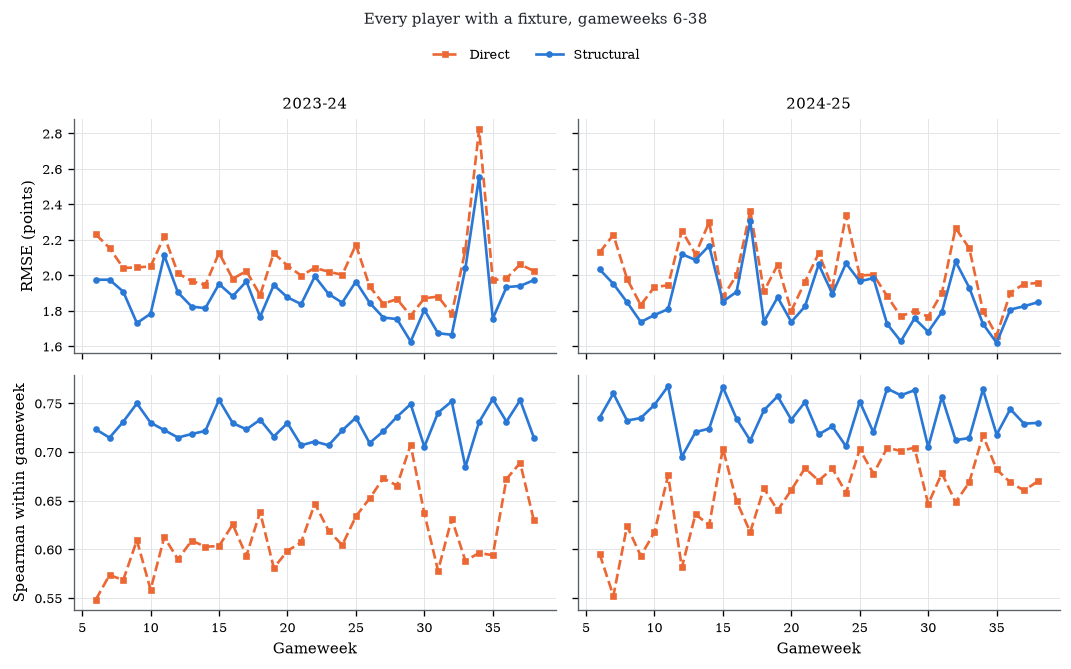

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5.2), sharex=True, sharey="row")
for k, (season, m) in enumerate(data.items()):
    g = per_gw(m)
    for p in ["direct", "struct"]:
        axes[0, k].plot(
            g.index, np.sqrt(g[(p, "mse")]), color=COLOR[p], label=LABEL[p], **STYLE[p]
        )
        axes[1, k].plot(
            g.index, g[(p, "rho")], color=COLOR[p], label=LABEL[p], **STYLE[p]
        )
    axes[0, k].set_title(f"20{season}")
    axes[1, k].set_xlabel("Gameweek")
axes[0, 0].set_ylabel("RMSE (points)")
axes[1, 0].set_ylabel("Spearman within gameweek")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))
fig.suptitle(
    "Every player with a fixture, gameweeks 6-38", y=1.06, fontsize=9, color=INK
)
fig.tight_layout()
save(fig, "predictor_by_gameweek")
plt.show()

## 5. Does the better prediction pick better players?

What matters downstream is ranking at the top. For each gameweek and predictor, take the top-k predicted players per
position (k = 2 GK, 5 DEF, 5 MID, 3 FWD, the shape of a squad, with no budget or club limits) and the single highest
predicted player (a captain pick), and count what they actually scored. The oracle (the best realised players) gives the
ceiling. `overlap` is the share of the 15 picks the two predictors have in common.

In [8]:
def top_k(m, col):
    ranked = m.sort_values(col, ascending=False, kind="stable")
    return pd.concat(
        [
            ranked[ranked["pos"] == pos].groupby("round").head(k)
            for pos, k in SQUAD.items()
        ]
    )


rows, cum = [], {}
for season, m in data.items():
    picks = {
        p: top_k(m, p) for p in ["direct", "struct", "struct_season", "total_points"]
    }
    caps = {p: m.loc[m.groupby("round")[p].idxmax()] for p in picks}
    pts = {p: picks[p].groupby("round")["total_points"].sum() for p in picks}
    cum[season] = pts
    common = [
        len(set(a.fpl_id) & set(b.fpl_id)) / 15
        for (_, a), (_, b) in zip(
            picks["direct"].groupby("round"), picks["struct"].groupby("round")
        )
    ]
    for p in picks:
        rows.append(
            {
                "season": season,
                "predictor": "Oracle" if p == "total_points" else LABEL[p],
                "top-15 points per GW": pts[p].mean(),
                "top-15 points, season": pts[p].sum(),
                "predicted per GW": picks[p].groupby("round")[p].sum().mean()
                if p != "total_points"
                else np.nan,
                "captain points per GW": caps[p]["total_points"].mean(),
                "captain points, season": caps[p]["total_points"].sum(),
                "overlap with other": np.mean(common)
                if p in ("direct", "struct")
                else np.nan,
            }
        )
    d = pts["struct"] - pts["direct"]
    print(
        f"{season}: structural − direct top-15 points per GW, mean {d.mean():+.2f}, "
        f"better in {(d > 0).sum()}/{len(d)} GWs, Wilcoxon p = {wilcoxon(d).pvalue:.3f}"
    )
pd.DataFrame(rows).set_index(["season", "predictor"])

23-24: structural − direct top-15 points per GW, mean +7.67, better in 22/33 GWs, Wilcoxon p = 0.006
24-25: structural − direct top-15 points per GW, mean +9.55, better in 18/33 GWs, Wilcoxon p = 0.036


top-15 points per GW  top-15 points, season  \
season predictor                                                              
23-24  Direct                                 67.303                   2221   
       Structural                             74.970                   2474   
       Structural, season only                75.182                   2481   
       Oracle                                177.121                   5845   
24-25  Direct                                 68.970                   2276   
       Structural                             78.515                   2591   
       Structural, season only                77.636                   2562   
       Oracle                                168.273                   5553   

                                predicted per GW  captain points per GW  \
season predictor                                                          
23-24  Direct                             70.083                  2.909   
       Structural                         78.956                  6.091   
       Structural, season only            78.719                  6.152   
       Oracle                                NaN                 18.606   
24-25  Direct                             79.003                  7.030   
       Structural                         76.895                  9.030   
       Structural, season only            78.478                  7.697   
       Oracle                                NaN                 18.091   

                                captain points, season  overlap with other  
season predictor                                                            
23-24  Direct                                       96               0.376  
       Structural                                  201               0.376  
       Structural, season only                     203                 NaN  
       Oracle                                      614                 NaN  
24-25  Direct                                      232               0.396  
       Structural                                  298               0.396  
       Structural, season only                     254                 NaN  
       Oracle                                      597                 NaN

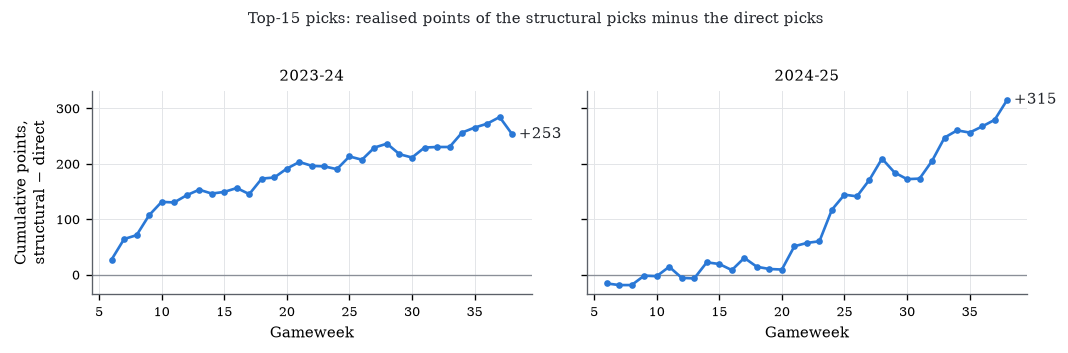

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
for ax, (season, pts) in zip(axes, cum.items()):
    d = (pts["struct"] - pts["direct"]).cumsum()
    ax.axhline(0, color=GREY, lw=0.8)
    ax.plot(d.index, d.values, color=COLOR["struct"], **STYLE["struct"])
    ax.annotate(
        f"{d.iloc[-1]:+.0f}",
        (d.index[-1], d.iloc[-1]),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        color=INK,
    )
    ax.set_title(f"20{season}")
    ax.set_xlabel("Gameweek")
axes[0].set_ylabel("Cumulative points,\nstructural − direct")
fig.suptitle(
    "Top-15 picks: realised points of the structural picks minus the direct picks",
    y=1.03,
    fontsize=9,
    color=INK,
)
fig.tight_layout()
save(fig, "predictor_top15")
plt.show()

## 6. Calibration

Mean actual points against mean prediction, in 20 equal-sized bins of each predictor's prediction (every player with a
fixture). On the diagonal, a predicted 5 means 5 points on average; for the optimiser the top bins matter most.

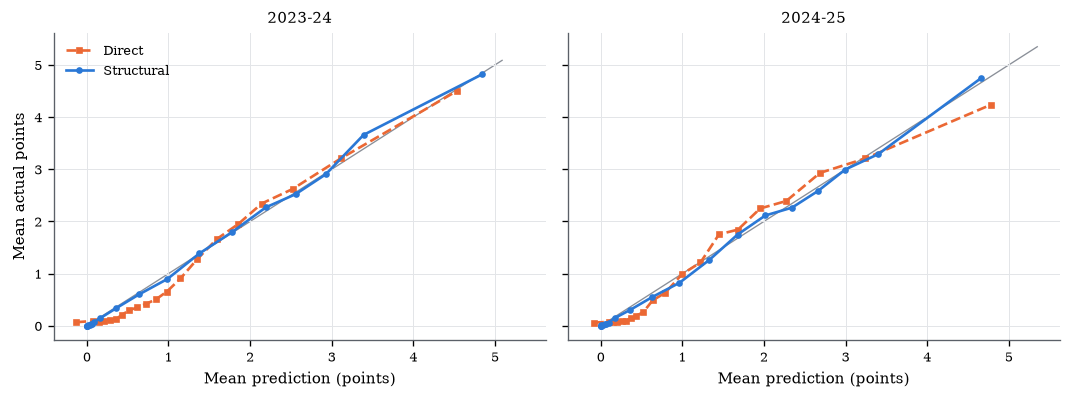

top decile: predicted  top decile: actual  \
season predictor                                               
23-24  Direct                      3.790               3.876   
       Structural                  4.093               4.188   
24-25  Direct                      4.014               3.706   
       Structural                  4.024               4.035   

                   bottom half: predicted  bottom half: actual  
season predictor                                                
23-24  Direct                       0.323                0.187  
       Structural                   0.042                0.032  
24-25  Direct                       0.290                0.155  
       Structural                   0.080                0.062

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharex=True, sharey=True)
rows = []
for ax, (season, m) in zip(axes, data.items()):
    for p in ["direct", "struct"]:
        b = pd.qcut(m[p].rank(method="first"), 20, labels=False)
        c = m.groupby(b).agg(pred=(p, "mean"), obs=("total_points", "mean"))
        ax.plot(c["pred"], c["obs"], color=COLOR[p], label=LABEL[p], **STYLE[p])
        top = m[m.groupby("round")[p].rank(ascending=False, pct=True) <= 0.10]
        rows.append(
            {
                "season": season,
                "predictor": LABEL[p],
                "top decile: predicted": top[p].mean(),
                "top decile: actual": top["total_points"].mean(),
                "bottom half: predicted": m.loc[b < 10, p].mean(),
                "bottom half: actual": m.loc[b < 10, "total_points"].mean(),
            }
        )
    lim = [0, max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lim, lim, color=GREY, lw=0.8, ls="-", zorder=0)
    ax.set_title(f"20{season}")
    ax.set_xlabel("Mean prediction (points)")
axes[0].set_ylabel("Mean actual points")
axes[0].legend(loc="upper left")
fig.tight_layout()
save(fig, "predictor_calibration")
plt.show()
pd.DataFrame(rows).set_index(["season", "predictor"])

## 7. Against FPL's xP

For reference, both predictions scored against FPL's `xP`, which neither is trained on. The structural README notes that
the source's same-gameweek `xP` was recorded after the match, so it is not a pre-match expectation. Gameweeks without `xP`
(26 in 2023-24; 22, 32 and 34 in 2024-25) are left out here. The last columns repeat the scores against actual points on
the same rows.

In [11]:
rows = []
for season, m in data.items():
    x = m[m["xP"].notna()]
    for p in ["direct", "struct"]:
        a, b = (
            scores(x["xP"], x[p], x["round"]),
            scores(x["total_points"], x[p], x["round"]),
        )
        rows.append(
            {
                "season": season,
                "predictor": LABEL[p],
                "rows": a["rows"],
                "xP: RMSE": a["RMSE"],
                "xP: MAE": a["MAE"],
                "xP: Spearman per GW": a["Spearman per GW"],
                "points: RMSE": b["RMSE"],
                "points: MAE": b["MAE"],
                "points: Spearman per GW": b["Spearman per GW"],
            }
        )
pd.DataFrame(rows).set_index(["season", "predictor"])

rows  xP: RMSE  xP: MAE  xP: Spearman per GW  \
season predictor                                                   
23-24  Direct      24735     1.334    0.890                0.631   
       Structural  24735     1.052    0.606                0.753   
24-25  Direct      21572     1.219    0.815                0.713   
       Structural  21572     1.018    0.625                0.789   

                   points: RMSE  points: MAE  points: Spearman per GW  
season predictor                                                       
23-24  Direct             2.046        1.135                    0.615  
       Structural         1.900        0.902                    0.727  
24-25  Direct             1.996        1.114                    0.654  
       Structural         1.881        0.959                    0.737

## 8. Summary

Gameweeks 6-38, same player-gameweeks for both predictors, both predicting points, scored against realised points.
The direct models are chosen by validation RMSE, like the structural model is scored.

* **The structural model is more accurate in both seasons.** Every player with a fixture: RMSE 1.90 vs 2.04 (2023-24)
  and 1.89 vs 2.00 (2024-25); within-gameweek Spearman 0.73 vs 0.62 and 0.74 vs 0.66. It has the lower squared error in
  every gameweek of both seasons (gameweek-clustered DM and Wilcoxon p < 1e-9), and in every position. Among players
  who played it is ahead on RMSE in 29/33 gameweeks in both seasons; MAE there is level.
* **Both are calibrated overall.** The direct model's bias is +0.09 and +0.05 points per player-gameweek, and its top
  decile is close (3.8 predicted vs 3.9 scored in 2023-24, 4.0 vs 3.7 in 2024-25). The structural model's is on target
  (about 4.0-4.1 predicted and scored). The direct model over-predicts players who will not play (bottom half: 0.29-0.32
  predicted vs 0.16-0.19 scored) and under-predicts those who do (-0.79 and -0.65): it has no separate model of whether
  a player plays.
* **The structural model picks better players.** Its top-15 picks score 7.7 (2023-24) and 9.5 (2024-25) more points per
  gameweek, better in 22/33 (p = 0.006) and 18/33 (p = 0.04) gameweeks. Its captain pick scores 6.1 and 9.0 points per
  gameweek against 2.9 and 7.0.
* **The previous season adds little.** Training the structural model on the previous season as well improves RMSE by
  about 0.005. The structural model's advantage doesn't come from the extra data.

Both direct pipelines (`playground/predictors/23-24`, `playground/predictors/24-25/predictor`) predict the gameweek's
points for every player with a fixture, train on players with minutes in the previous 3 gameweeks, have `n_fixtures` as
an input, and choose and score models by RMSE. Choosing by MAE instead picked svr almost every time, whose shrunk
predictions under-predicted the top decile by 0.6-1.1 points and cost 5-7 points per gameweek in the top-15 picks.

The structural RMSEs here (about 1.89-1.90) are higher than in the structural README (1.85-1.88). This comparison starts at
GW6 and scores double-gameweek players on their gameweek total, while the README scores each fixture separately.